# Pulse Shaping: Cosine and Raised-Cosine Pulse Shaping for BPSK

Every symbol you transmit has to be given some shape in time -- held at a value for a while,
then moved to the next one. The simplest shape holds the value flat for the whole symbol
period and switches instantly: a rectangular pulse. That instant switch is exactly the
problem: it spreads energy across a very wide range of frequencies, wasting bandwidth. This
worksheet builds two smoother alternatives -- a **cosine pulse** and a **raised-cosine
pulse** -- and lets you see the difference both in the spectrum and in how each pulse holds
up once you push a simulated channel's frequency offset and noise around.

You'll implement the pulse shapes yourself, piece by piece, with the theory laid out just
above each blank. Everything *around* the pulses -- the simulated channel, frame sync, and
the plotting -- is given in full, so you can focus on the part this worksheet is actually
about.

## Configuration

Two settings here matter more than the rest: `CFO_HZ` is a frequency offset ("rotation")
the simulated channel applies, and `SNR_DB` is how noisy that channel is. Set `CFO_HZ = 0`
to turn rotation off, or `SNR_DB = None` to turn noise off, independently of each other --
you'll want to come back and change these once everything below is working.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

In [2]:
SPS            = 32          # samples per symbol
N_BITS         = 4000       # number of BPSK bits to simulate
PREAMBLE_LEN   = 2000       # samples in the constant-value preamble (sync + phase/gain ref)
PREAMBLE_SCALE = 1.5        # preamble amplitude

RC_BETA = 0.35    # raised-cosine roll-off factor (0 = narrowest bandwidth, slowest tails;
                  # 1 = widest bandwidth, fastest tails)
RC_SPAN = 6       # raised-cosine pulse span, in symbol periods

FS = 2.0e6        # nominal sample rate (Hz) -- only here so CFO_HZ means something physical

# --- The two channel impairments -----------------------------------------
CFO_HZ = 300      # frequency offset ("rotation"), in Hz. Set to 0 to turn rotation off.
SNR_DB = 12       # channel signal-to-noise ratio, in dB. Set to None to turn noise off.

RANDOM_SEED = None   # set an integer for a reproducible run, or leave as None

## Task 1: The Rectangular Pulse (Baseline)

Given in full -- this is the pulse everything else in this worksheet gets compared against.
`sps` samples, all equal to 1: the symbol's value, held flat, then switched instantly at the
boundary. That instant switch is what a spectrum "sees" as high-frequency content, which is
exactly why it's worth building something smoother.

In [3]:
def rect_pulse(sps):
    '''Rectangular pulse: sps samples, all equal to 1.'''
    return np.ones(sps)


rect_arr = rect_pulse(SPS)
print(rect_arr)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1.]


A quick note on naming before Task 2: "raised cosine" gets used for two different
things in this field, which trips people up constantly. The taper you're about to build is
sometimes casually called a "raised-cosine window" -- and it does look like one -- but that's
a different animal from the "raised-cosine pulse" in Task 4, which is a specific pulse
designed to satisfy Nyquist's zero-ISI criterion. To keep the two straight, this worksheet
just calls the first one **the cosine pulse**, full stop, and saves "raised cosine" for
Task 4.

## Task 2: The Cosine Pulse

The rectangular pulse jumps from 0 to its full value instantly at the start of the symbol,
and back down just as abruptly at the end. Replace both jumps with a smooth taper that
touches exactly zero at both edges and rises to its peak in the middle:

$$g[n] = \tfrac{1}{2}\left(1 - \cos\left(\dfrac{2\pi n}{\text{sps} - 1}\right)\right), \qquad
n = 0, 1, \dots, \text{sps}-1$$

`n = np.arange(sps)` already gives you $n = 0, 1, \dots, \text{sps}-1$ below -- your job is
to turn the formula above into the one line that builds `pulse` from it.

In [4]:
def cosine_pulse(sps):
    '''
    One-symbol cosine-tapered pulse:
        g[n] = 0.5 * (1 - cos(2*pi*n/(sps-1)))
    '''
    n = np.arange(sps)
    pulse = np.sqrt(0.5 * (1 - np.cos(2 * np.pi * n / (sps - 1))))
    return pulse


cos_arr = cosine_pulse(SPS)
print(np.round(cos_arr, 3))


[0.    0.101 0.201 0.299 0.394 0.485 0.571 0.651 0.725 0.791 0.849 0.898
 0.938 0.968 0.988 0.999 0.999 0.988 0.968 0.938 0.898 0.849 0.791 0.725
 0.651 0.571 0.485 0.394 0.299 0.201 0.101 0.   ]


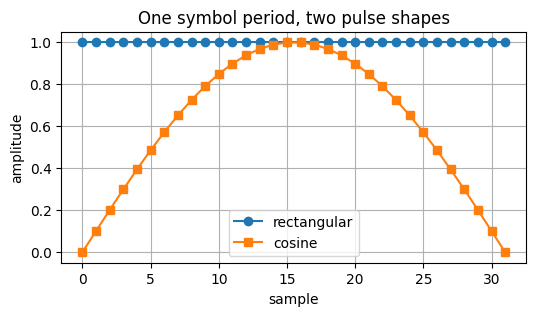

In [5]:
plt.figure(figsize=(6, 3))
plt.plot(rect_arr, 'o-', label='rectangular')
plt.plot(cos_arr, 's-', label='cosine')
plt.xlabel('sample')
plt.ylabel('amplitude')
plt.title('One symbol period, two pulse shapes')
plt.legend()
plt.grid(True)
plt.show()

## Task 3: General Pulse Shaping and Matched Filtering

Rather than writing separate transmit/receive code for each pulse, it's worth building this
once in a form that works for *any* pulse -- rectangular, cosine, or (in Task 4) something
much longer. `pulse_shape(symbols, pulse, sps)` does the transmit side: zero-stuff the
symbols (one nonzero sample every `sps` samples) and convolve with the pulse. That part is
given in full below, since the idea doesn't depend on which pulse you use.

The receive side, `matched_filter_downsample`, is the theoretical payoff of this whole
section. The filter that maximizes output SNR for a known pulse $g[n]$ in noise is its
time-reverse, $h[n] = g^*[-n]$ -- correlating against that kernel is provably the best
linear way to pull the symbol back out of a noisy, pulse-shaped waveform. There's one more
piece needed to land back on the *actual* transmitted amplitude rather than some multiple of
it: divide by the pulse's own energy.

$$\text{kernel} = \dfrac{\text{conj}(\text{pulse reversed})}{\sum |\text{pulse}|^2}$$

Build that kernel, and the rest -- convolving with it and picking off one sample per symbol
-- is given.

In [6]:
def pulse_shape(symbols, pulse, sps):
    '''Zero-stuff symbols at sps-sample spacing, then convolve with the pulse.'''
    n_symbols = len(symbols)
    zero_stuffed = np.zeros(n_symbols * sps, dtype=complex)
    zero_stuffed[0::sps] = symbols
    return np.convolve(zero_stuffed, pulse)   # full convolution -- keep the tail


def matched_filter_downsample(samples, pulse, sps):
    '''
    Matched filter with energy normalization.
    The kernel is the conjugate time-reverse of the pulse.
    '''
    pulse = np.asarray(pulse)
    kernel = np.conj(pulse[::-1]) / np.sum(np.abs(pulse) ** 2)
    filtered = np.convolve(samples, kernel)
    delay = len(pulse) - 1
    return filtered[delay::sps]


# Sanity check
test_symbols = np.array([1 + 0j, -1 + 0j, 1 + 0j, -1 + 0j])
shaped = pulse_shape(test_symbols, cos_arr, SPS)
recovered = matched_filter_downsample(shaped, cos_arr, SPS)
print("Original: ", test_symbols)
print("Recovered:", np.round(recovered[:len(test_symbols)], 3))


Original:  [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]
Recovered: [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]


## BPSK Bits and Symbols

Given -- bit 1 maps to $+1$, bit 0 maps to $-1$, and decoding is a sign check on the real
part. Nothing about this changes with the pulse shape.

In [7]:
def generate_bits(n):
    return np.random.randint(0, 2, n)


def bits_to_bpsk(bits):
    return np.where(bits == 1, 1 + 0j, -1 + 0j)


def bpsk_to_bits(symbols):
    return (symbols.real > 0).astype(int)

## Frame Construction

Given -- a frame is a constant-value preamble (used for sync and as a phase/gain reference)
followed by the pulse-shaped payload. `build_frame` takes the pulse itself as an argument,
so the same function builds a frame for any of the pulses in this worksheet.

In [8]:
def build_frame(bits, pulse, sps, preamble_len, preamble_scale):
    symbols = bits_to_bpsk(bits)
    payload = pulse_shape(symbols, pulse, sps)
    preamble = np.full(preamble_len, preamble_scale + 0j, dtype=np.complex64)
    return np.concatenate([preamble, payload]).astype(np.complex64)

## The Simulated Channel

Given in full. `apply_channel` is what `CFO_HZ` and `SNR_DB` from the Configuration cell
actually control. It always applies some unknown gain and phase (a real receiver never gets
to skip dealing with those), then the frequency offset `cfo_hz`, then Gaussian noise sized to
`snr_db`. Finally it drops the result at a random position inside a larger noise-only
buffer -- a real receiver has to *find* the frame first, not just assume it starts at sample
zero, and Task 3's matched filter is useless until that search succeeds.

In [9]:
def apply_channel(frame, fs, cfo_hz=0.0, snr_db=None, phase_offset=None, gain=None,
                   buffer_margin=2.2):
    if phase_offset is None:
        phase_offset = np.random.uniform(-np.pi, np.pi)
    if gain is None:
        gain = np.random.uniform(0.7, 1.3)

    n = np.arange(len(frame))
    out = frame * gain * np.exp(1j * phase_offset) * np.exp(1j * 2 * np.pi * cfo_hz * n / fs)

    if snr_db is not None:
        sig_power = np.mean(np.abs(out) ** 2)
        noise_power = sig_power / (10 ** (snr_db / 10))
        noise_std = np.sqrt(noise_power / 2)
    else:
        noise_std = 0.0

    def complex_noise(n_samples):
        if noise_std == 0.0:
            return np.zeros(n_samples, dtype=complex)
        return noise_std * (np.random.randn(n_samples) + 1j * np.random.randn(n_samples))

    out = out + complex_noise(len(frame))

    buffer_size = int(np.ceil(buffer_margin * len(frame)))
    rx = complex_noise(buffer_size)
    max_start = max(buffer_size - len(frame), 1)
    start = np.random.randint(0, max_start)
    rx[start:start + len(frame)] = out
    return rx.astype(np.complex64)

## Frame Sync and Correction

Given in full. `find_frame_start` checks *every* possible position for the loudest
preamble-length window -- full resolution, not a coarse stride, because the cosine and
raised-cosine pulses vary continuously within a symbol, so landing even a few samples off
the true start puts every downstream matched-filter sample at the wrong point on the pulse.

`correct_frame` undoes the frequency offset, then the phase and gain, using the preamble as
a reference. The frequency estimate splits the preamble into two back-to-back blocks and
correlates them, rather than comparing only adjacent samples -- that longer lag makes the
phase difference between blocks much bigger relative to the noise, which starts to matter
once the payload is long enough for a small residual frequency error to drift the phase
noticeably before the frame ends.

In [10]:
def find_frame_start(rx_samples, preamble_len, frame_len):
    '''
    Find the start of the frame using a sliding preamble-energy metric.
    The preamble is deliberately much longer than a symbol, so the correct
    location produces a strong sustained-energy peak.
    '''
    rx_samples = np.asarray(rx_samples)
    if len(rx_samples) < preamble_len:
        raise ValueError("RX buffer is shorter than the preamble.")

    power = np.abs(rx_samples) ** 2
    window_energy = np.convolve(power, np.ones(preamble_len), mode='valid')
    start = int(np.argmax(window_energy))
    return start


def correct_frame(frame_slice, preamble_len, preamble_value, fs):
    '''
    Estimate CFO from two consecutive preamble blocks, then estimate the
    remaining complex gain (phase + amplitude) from the corrected preamble.
    '''
    frame_slice = np.asarray(frame_slice, dtype=complex)
    half = preamble_len // 2
    if half < 1 or len(frame_slice) < preamble_len:
        raise ValueError("Frame is too short for the requested preamble.")

    # Two-block frequency estimate.
    a = frame_slice[:half]
    b = frame_slice[half:2*half]
    corr = np.sum(np.conj(a) * b)
    phase_step = np.angle(corr)
    lag = half
    f_hat = phase_step * fs / (2 * np.pi * lag)

    n = np.arange(len(frame_slice))
    cfo_corrected = frame_slice * np.exp(-1j * 2 * np.pi * f_hat * n / fs)

    # Estimate complex gain from the known constant preamble.
    known = complex(preamble_value)
    gain_hat = np.mean(cfo_corrected[:preamble_len] / known)

    corrected = cfo_corrected / gain_hat
    return corrected, f_hat


def compute_ber(tx_bits, rx_bits):
    n = min(len(tx_bits), len(rx_bits))
    if n == 0:
        return 0, 0, np.nan
    errors = int(np.sum(tx_bits[:n] != rx_bits[:n]))
    return errors, n, errors / n


## Part 2: The Raised-Cosine Pulse

The cosine pulse helped, but it's still confined to exactly one symbol period, which limits
how smooth it can be. Real bandwidth-efficient systems go a step further: let a single
symbol's pulse spread out over *several* symbol periods, so its edges can taper far more
gradually than anything squeezed into one symbol period alone.

Spreading a pulse across several symbols sounds like it should immediately cause
inter-symbol interference (ISI) -- neighboring symbols' pulses now genuinely overlap in
time. The raised-cosine pulse is the classic solution: it's shaped so that, sampled at
exactly the right instant, every neighboring symbol's contribution is precisely zero. Only
the pulse's own peak survives at its own sampling instant. This is Nyquist's zero-ISI
criterion in action, and Task 5 lets you check it directly.

## Task 4: Build the Raised-Cosine Pulse

In continuous time, with $t$ measured in units of symbol periods and $\beta$ the roll-off
factor:

$$g(t) = \text{sinc}(t)\,\dfrac{\cos(\pi \beta t)}{1 - (2\beta t)^2}$$

(`np.sinc` in NumPy is already the normalized sinc, $\sin(\pi x)/(\pi x)$, so `np.sinc(t)` is
exactly $\text{sinc}(t)$ here -- no extra $\pi$ needed.) This formula has two problem points:
$t=0$ (where the fraction is $0/0$) and $t = \pm\frac{1}{2\beta}$ (where the denominator
vanishes). Both are handled for you below -- $g(0) = 1$, and
$g\!\left(\pm\frac{1}{2\beta}\right) = \frac{\pi}{4}\text{sinc}\!\left(\frac{1}{2\beta}\right)$.
Your job is the general-case formula, evaluated everywhere *except* those two problem
points.

In [11]:
def raised_cosine_pulse(sps, beta, span):
    n = np.arange(-span * sps // 2, span * sps // 2 + 1)
    t = n / sps

    g = np.zeros_like(t, dtype=float)

    is_zero = np.isclose(t, 0.0)
    g[is_zero] = 1.0

    if beta > 0:
        is_singular = np.isclose(np.abs(t), 1 / (2 * beta))
        g[is_singular] = (np.pi / 4) * np.sinc(1 / (2 * beta))
    else:
        is_singular = np.zeros_like(t, dtype=bool)

    general = ~is_zero & ~is_singular
    t_g = t[general]
    g[general] = (
        np.sinc(t_g)
        * np.cos(np.pi * beta * t_g)
        / (1 - (2 * beta * t_g) ** 2)
    )

    return g


rc_arr = raised_cosine_pulse(SPS, RC_BETA, RC_SPAN)
print(f"Pulse length: {len(rc_arr)} samples ({RC_SPAN} symbol periods, peak at index "
      f"{len(rc_arr)//2})")


Pulse length: 193 samples (6 symbol periods, peak at index 96)


Run the cell below to see all three pulses together, time and frequency. In the
time-domain plot, notice how the raised-cosine pulse visibly extends well beyond one symbol
period on either side, unlike the other two -- and yet, per the frequency-domain plot, it's
the most bandwidth-efficient of the three for the same symbol rate. Given in full.

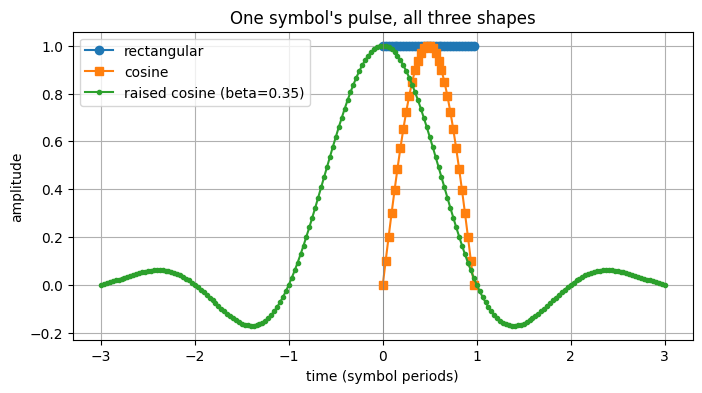

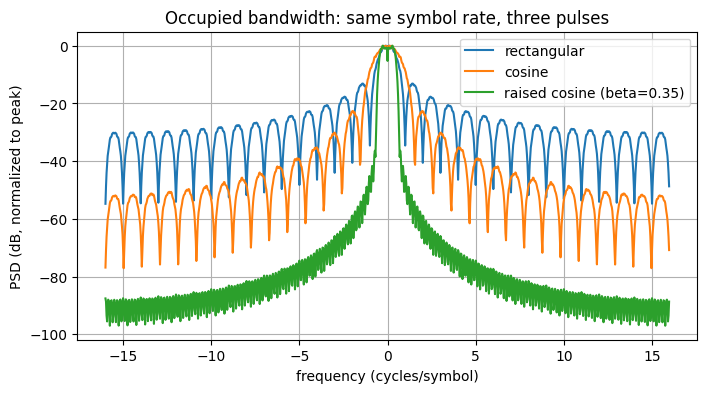

In [12]:
plt.figure(figsize=(8, 4))
t_short = np.arange(SPS) / SPS
t_rc = (np.arange(len(rc_arr)) - len(rc_arr) // 2) / SPS
plt.plot(t_short, rect_arr, 'o-', label='rectangular')
plt.plot(t_short, cos_arr, 's-', label='cosine')
plt.plot(t_rc, rc_arr, '.-', label=f'raised cosine (beta={RC_BETA})')
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('time (symbol periods)')
plt.ylabel('amplitude')
plt.title("One symbol's pulse, all three shapes")
plt.legend()
plt.grid(True)
plt.show()

demo_bits = generate_bits(4000)
demo_symbols = bits_to_bpsk(demo_bits)
plt.figure(figsize=(8, 4))
for pulse, label in [(rect_arr, 'rectangular'), (cos_arr, 'cosine'),
                      (rc_arr, f'raised cosine (beta={RC_BETA})')]:
    waveform = pulse_shape(demo_symbols, pulse, SPS)
    f, psd = welch(waveform, fs=SPS, nperseg=1024, return_onesided=False)
    f, psd = np.fft.fftshift(f), np.fft.fftshift(psd)
    plt.plot(f, 10 * np.log10(psd / psd.max()), label=label)
plt.xlabel('frequency (cycles/symbol)')
plt.ylabel('PSD (dB, normalized to peak)')
plt.title('Occupied bandwidth: same symbol rate, three pulses')
plt.legend()
plt.grid(True)
plt.show()

## Task 5: Confirm the Zero-ISI Property

Sample the raised-cosine pulse once per symbol period, centered on its own peak. If
Nyquist's criterion holds, every sample except the center one should come out essentially
zero -- even though the plot above just showed the pulse is clearly *not* zero at most of
those same points when you look at it continuously. What's zero is specifically the value
at whole-symbol-period multiples away from center; in between, the pulse (and real
neighboring symbols' pulses) are very much nonzero.

Each symbol period away from `center` is `SPS` samples in the array -- turn that into the
array of indices to sample.

Raised-cosine pulse, sampled once per symbol period around the peak:
  -3 symbol periods from center: g =  0.000000
  -2 symbol periods from center: g = -0.000000
  -1 symbol periods from center: g =  0.000000
  +0 symbol periods from center: g =  1.000000
  +1 symbol periods from center: g =  0.000000
  +2 symbol periods from center: g = -0.000000
  +3 symbol periods from center: g =  0.000000


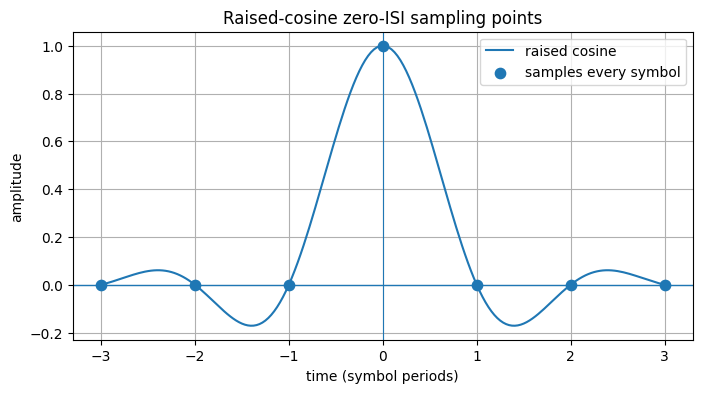

In [13]:
center = len(rc_arr) // 2
offsets = np.arange(-(RC_SPAN // 2), RC_SPAN // 2 + 1)
sample_indices = center + offsets * SPS

print("Raised-cosine pulse, sampled once per symbol period around the peak:")
for k, idx in zip(offsets, sample_indices):
    print(f"  {k:+d} symbol periods from center: g = {rc_arr[idx]: .6f}")

# Plot the zero-ISI samples explicitly.
plt.figure(figsize=(8, 4))
plt.plot(t_rc, rc_arr, label="raised cosine")
plt.scatter(offsets, rc_arr[sample_indices], s=55, zorder=3, label="samples every symbol")
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=0.8)
plt.xlabel("time (symbol periods)")
plt.ylabel("amplitude")
plt.title("Raised-cosine zero-ISI sampling points")
plt.grid(True)
plt.legend()
plt.show()


## Run All Three Pulses and Compare

There is an important timing detail in the direct-sampling comparison.

The rectangular and one-symbol cosine pulses are confined to one symbol interval, so
splitting the payload into blocks of `SPS` samples happens to line up with the symbols.

The raised-cosine pulse is different: it extends over several symbol periods. Its peak is
at the **center of the pulse**, not at `payload[0]`. Therefore blindly averaging
`payload[0:SPS]`, or taking `payload[SPS//2]`, samples the wrong part of the
raised-cosine waveform.

We therefore compare:

- **aligned average:** average `SPS` samples centered on the pulse peak;
- **aligned middle:** one sample at the pulse peak / symbol timing instant;
- **naive average:** the original unaligned average, retained as a diagnostic;
- **matched filter:** the proper pulse-matched reference receiver.

For the raised-cosine pulse, the aligned middle sample is taken at its zero-ISI sampling
point. The aligned average is a deliberately different detector: it averages nearby
samples, including some contribution from neighboring symbols.

In [14]:
def symbol_center_offset(pulse):
    """Sample offset of the pulse peak relative to the start of the convolution output."""
    return int(round((len(pulse) - 1) / 2))


def decode_by_symbol_average(samples, sps, pulse):
    """
    Average SPS samples centered on the actual pulse peak for each symbol.
    This is timing-aligned; it is different from blindly reshaping payload.
    """
    center = symbol_center_offset(pulse)
    start = center - sps // 2
    n_symbols = (len(samples) - start - sps) // sps + 1
    if n_symbols <= 0:
        return np.array([], dtype=complex)

    indices = (
        start
        + np.arange(n_symbols)[:, None] * sps
        + np.arange(sps)[None, :]
    )
    return np.mean(samples[indices], axis=1)


def decode_by_middle_sample(samples, sps, pulse):
    """Use one sample at the actual pulse center for each symbol."""
    center = symbol_center_offset(pulse)
    n_symbols = (len(samples) - center - 1) // sps + 1
    if n_symbols <= 0:
        return np.array([], dtype=complex)
    return samples[center:center + n_symbols * sps:sps]


def decode_naive_average(samples, sps):
    """Intentionally unaligned average, retained as a diagnostic baseline."""
    n_symbols = len(samples) // sps
    x = samples[:n_symbols * sps].reshape(n_symbols, sps)
    return np.mean(x, axis=1)


def run_pulse(name, pulse, bits, sps, preamble_len, preamble_scale, fs, cfo_hz, snr_db):
    frame = build_frame(bits, pulse, sps, preamble_len, preamble_scale)
    frame_len = preamble_len + len(bits) * sps + len(pulse) - 1

    rx = apply_channel(frame, fs, cfo_hz=cfo_hz, snr_db=snr_db)

    start = find_frame_start(rx, preamble_len, frame_len)
    frame_slice = rx[start:start + frame_len]
    corrected, f_hat = correct_frame(
        frame_slice, preamble_len, preamble_scale + 0j, fs
    )

    payload = corrected[preamble_len:]

    # Reference receiver: matched filter + symbol-rate sampling.
    mf_syms = matched_filter_downsample(payload, pulse, sps)
    mf_bits = bpsk_to_bits(mf_syms)
    mf_errors, mf_total, mf_ber = compute_ber(bits, mf_bits)

    # Timing-aligned direct detectors.
    avg_syms = decode_by_symbol_average(payload, sps, pulse)
    mid_syms = decode_by_middle_sample(payload, sps, pulse)

    avg_bits = bpsk_to_bits(avg_syms)
    mid_bits = bpsk_to_bits(mid_syms)

    avg_errors, avg_total, avg_ber = compute_ber(bits, avg_bits)
    mid_errors, mid_total, mid_ber = compute_ber(bits, mid_bits)

    # Deliberately naive version, useful for diagnosing timing errors.
    naive_avg_syms = decode_naive_average(payload, sps)
    naive_avg_bits = bpsk_to_bits(naive_avg_syms)
    naive_errors, naive_total, naive_ber = compute_ber(bits, naive_avg_bits)

    result = {
        "name": name, "pulse": pulse, "frame": frame, "rx": rx,
        "start": start, "frame_slice": frame_slice, "corrected": corrected,
        "payload": payload, "f_hat": f_hat,
        "mf_syms": mf_syms, "mf_bits": mf_bits, "mf_ber": mf_ber,
        "avg_syms": avg_syms, "avg_bits": avg_bits, "avg_ber": avg_ber,
        "mid_syms": mid_syms, "mid_bits": mid_bits, "mid_ber": mid_ber,
        "naive_avg_syms": naive_avg_syms, "naive_avg_bits": naive_avg_bits,
        "naive_avg_ber": naive_ber,
        "errors": {
            "matched_filter": mf_errors, "average": avg_errors,
            "middle": mid_errors, "naive_average": naive_errors
        }
    }

    print(
        f"{name:<16} CFO est: {f_hat:8.1f} Hz | "
        f"MF BER: {mf_ber:.4e} | "
        f"aligned average BER: {avg_ber:.4e} | "
        f"aligned middle BER: {mid_ber:.4e} | "
        f"naive average BER: {naive_ber:.4e}"
    )
    return result


if RANDOM_SEED is not None:
    np.random.seed(RANDOM_SEED)

bits = generate_bits(N_BITS)

pulses = {
    'rectangular': rect_arr,
    'cosine': cos_arr,
    'raised cosine': rc_arr,
}

print(
    f"Channel: CFO = {CFO_HZ} Hz{' (off)' if CFO_HZ == 0 else ''}, "
    f"SNR = {SNR_DB} dB{' (noise off)' if SNR_DB is None else ''}\n"
)

results_by_pulse = {}
for name, pulse in pulses.items():
    results_by_pulse[name] = run_pulse(
        name, pulse, bits, SPS, PREAMBLE_LEN, PREAMBLE_SCALE,
        FS, CFO_HZ, SNR_DB
    )

rx_syms_by_pulse = {
    name: result["mf_syms"] for name, result in results_by_pulse.items()
}

Channel: CFO = 300 Hz, SNR = 12 dB

rectangular      CFO est:    302.7 Hz | MF BER: 0.0000e+00 | aligned average BER: 0.0000e+00 | aligned middle BER: 2.5000e-04 | naive average BER: 0.0000e+00
cosine           CFO est:    300.1 Hz | MF BER: 0.0000e+00 | aligned average BER: 0.0000e+00 | aligned middle BER: 0.0000e+00 | naive average BER: 0.0000e+00
raised cosine    CFO est:    299.6 Hz | MF BER: 0.0000e+00 | aligned average BER: 0.0000e+00 | aligned middle BER: 0.0000e+00 | naive average BER: 4.5100e-01


## Received Constellations

Given. After correction, all three should land in two tight clusters at $\pm 1$. Turn the
noise up (lower `SNR_DB`) and the clusters should spread out; turn the rotation up (higher
`CFO_HZ`) with the noise low and watch how much of that rotation the correction step can
still undo.

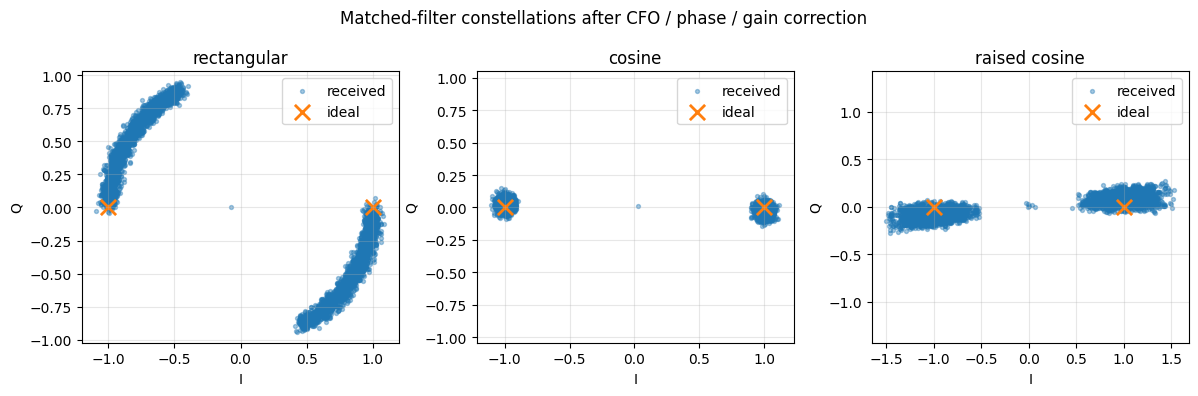

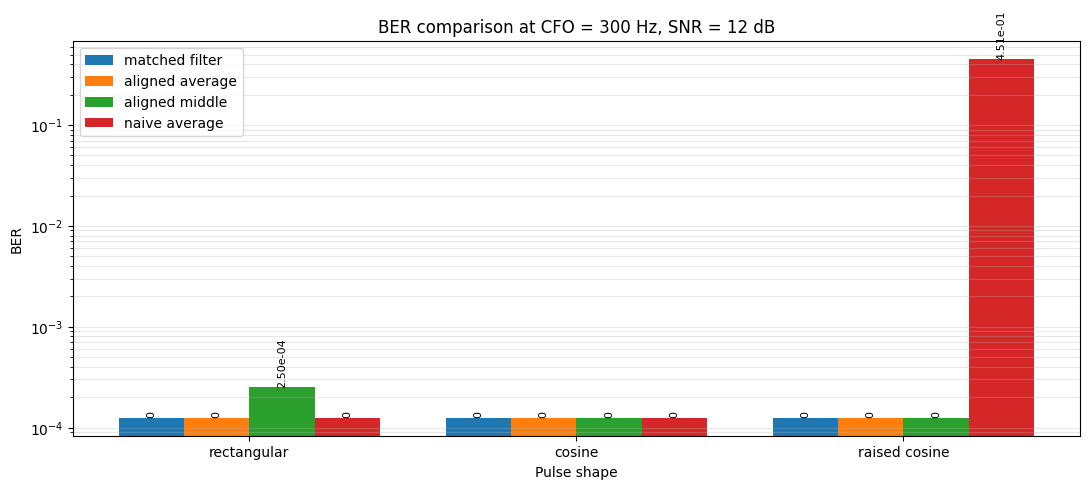

In [15]:
# ============================================================
# RECEIVED CONSTELLATIONS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

ideal = np.array([-1 + 0j, 1 + 0j])

for ax, (name, result) in zip(axes, results_by_pulse.items()):
    rx_syms = result["mf_syms"]

    ax.scatter(
        rx_syms.real,
        rx_syms.imag,
        s=8,
        alpha=0.4,
        label="received"
    )

    ax.scatter(
        ideal.real,
        ideal.imag,
        marker="x",
        s=120,
        linewidths=2,
        label="ideal"
    )

    ax.set_title(name)
    ax.set_xlabel("I")
    ax.set_ylabel("Q")
    ax.axis("equal")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "Matched-filter constellations after CFO / phase / gain correction"
)
plt.tight_layout()
plt.show()


# ============================================================
# BER COMPARISON AT THE CURRENT CHANNEL SETTINGS
# ============================================================

method_names = [
    "matched filter",
    "aligned average",
    "aligned middle",
    "naive average"
]

method_keys = [
    "mf_ber",
    "avg_ber",
    "mid_ber",
    "naive_avg_ber"
]

x = np.arange(len(pulses))
width = 0.20

fig, ax = plt.subplots(figsize=(11, 5))

# A zero BER cannot be displayed on a logarithmic axis.
# Replace zero ONLY for visualization; printed BER values remain zero.
BER_FLOOR = 0.5 / N_BITS

for j, (method_key, method_name) in enumerate(
    zip(method_keys, method_names)
):
    vals = np.array([
        results_by_pulse[name][method_key]
        for name in pulses
    ], dtype=float)

    vals_plot = np.maximum(vals, BER_FLOOR)

    bars = ax.bar(
        x + (j - 1.5) * width,
        vals_plot,
        width,
        label=method_name
    )

    # Show the actual measured value above every bar.
    for bar, value in zip(bars, vals):
        label = "0" if value == 0 else f"{value:.2e}"
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            max(bar.get_height(), BER_FLOOR),
            label,
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(pulses)
ax.set_xlabel("Pulse shape")
ax.set_ylabel("BER")
ax.set_title(
    f"BER comparison at CFO = {CFO_HZ} Hz, SNR = {SNR_DB} dB"
)
ax.grid(True, which="both", axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# SNR vs BER
# ============================================================
# Cell 35 below performs the SNR sweep and creates the
# detailed SNR-vs-BER plots. Do NOT reference ber_mf,
# ber_avg, or ber_mid here; those variables do not exist
# in this notebook. The sweep results are stored in ber_sweep.


## Intermediate Results: Channel, Synchronization, Correction, and Detection

The following plots expose the complete receive chain for each pulse:

1. transmitted waveform,
2. received buffer and frame-start metric,
3. received frame before correction,
4. corrected frame,
5. matched-filter output,
6. direct per-symbol average versus middle-sample decisions,
7. local symbol waveforms showing why the two direct detectors behave differently.

Only a short window is plotted for long waveforms so the individual samples remain visible.


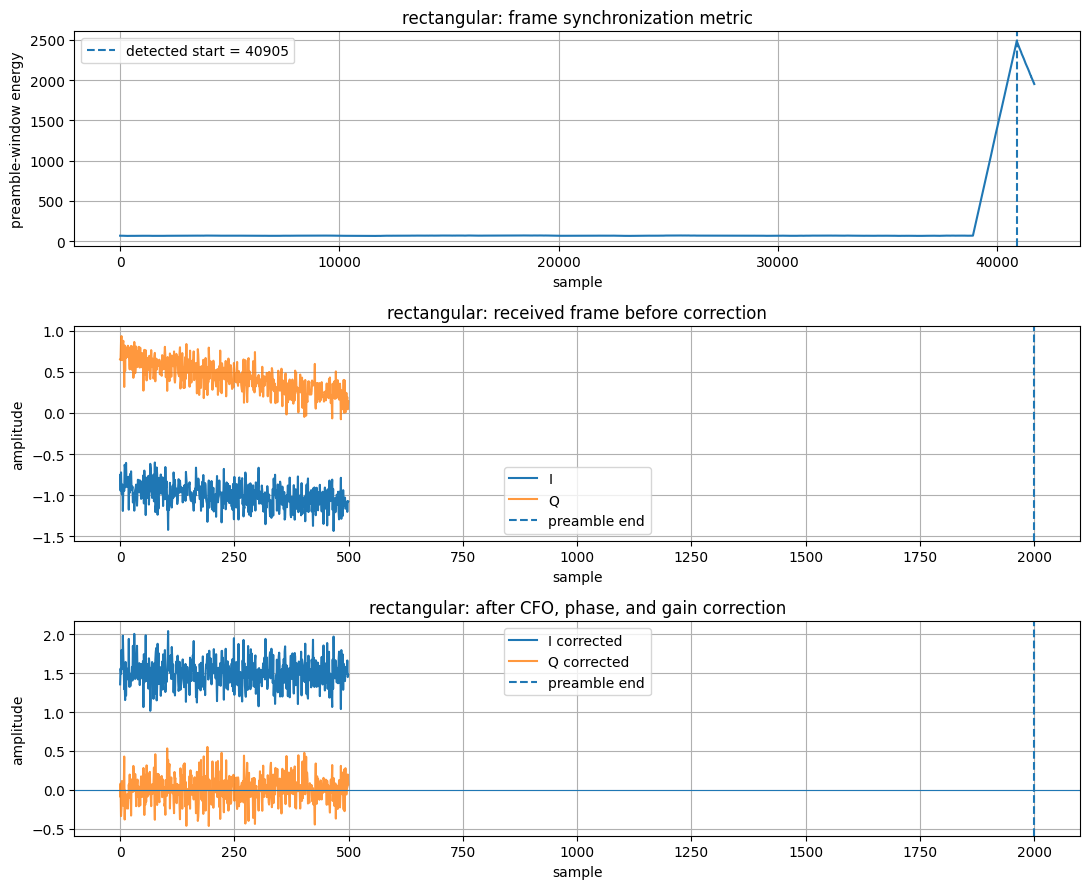

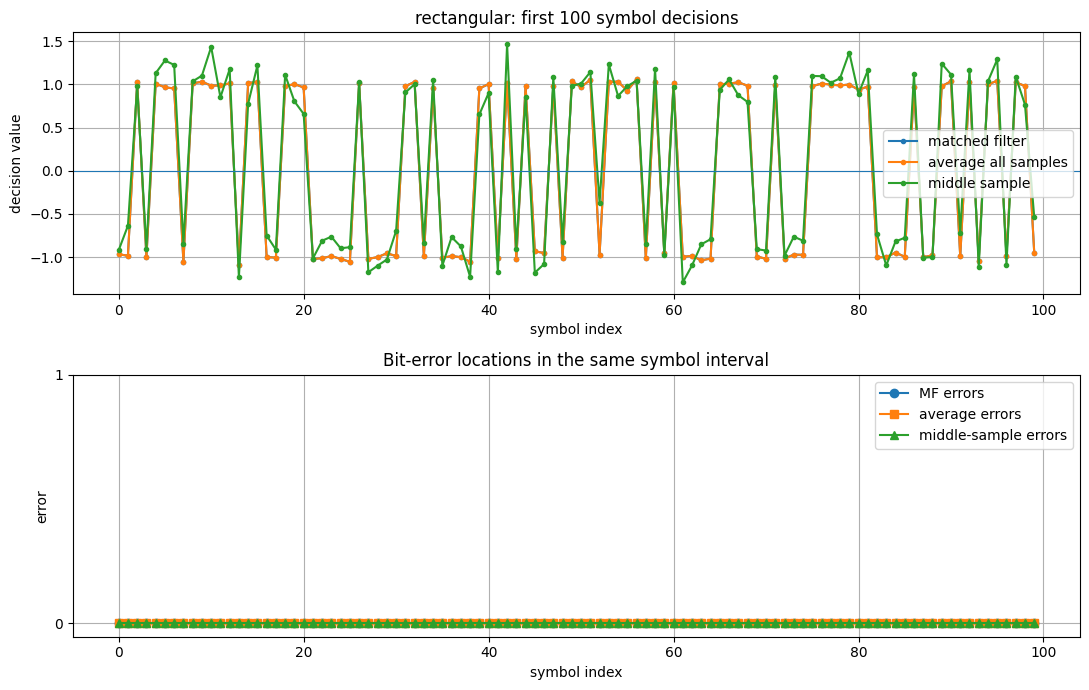

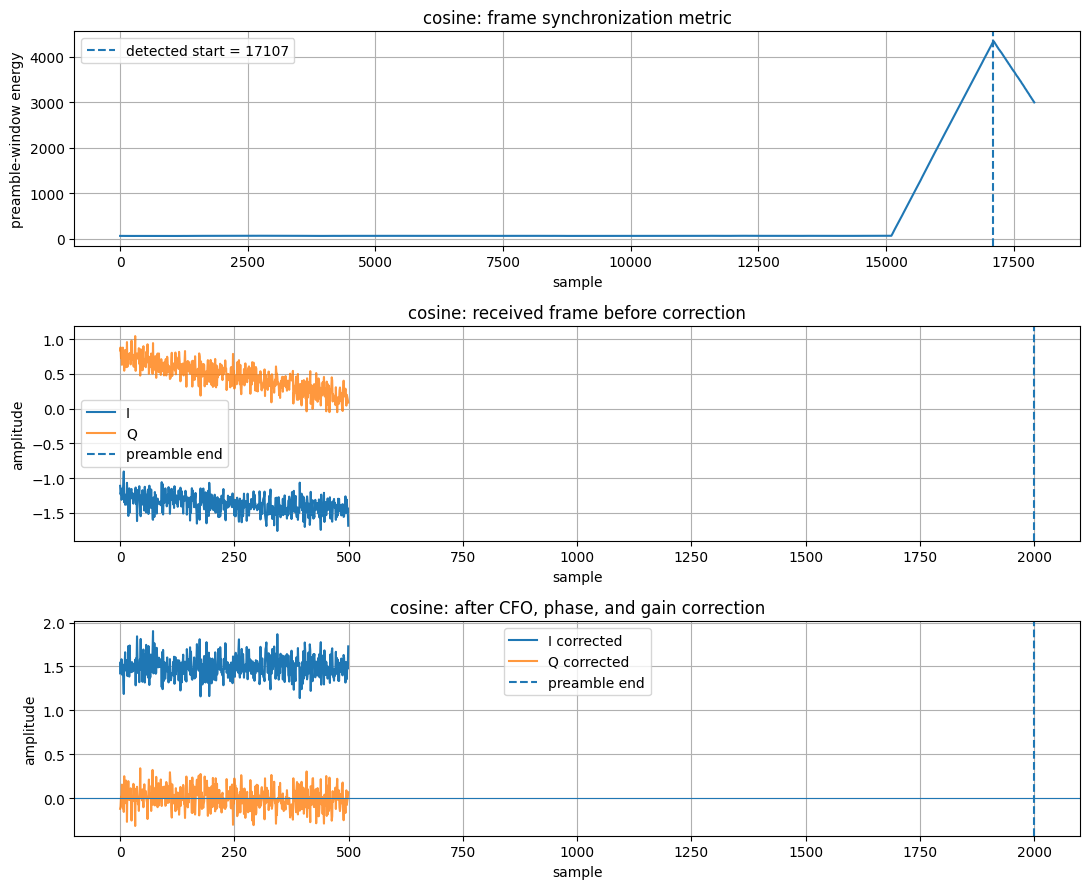

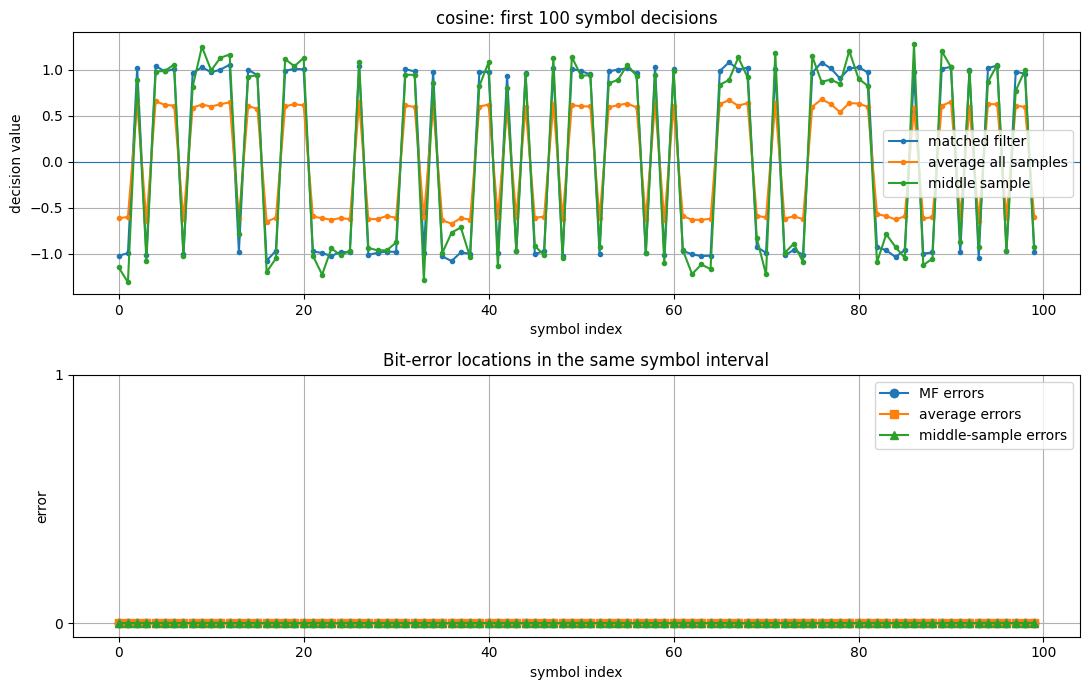

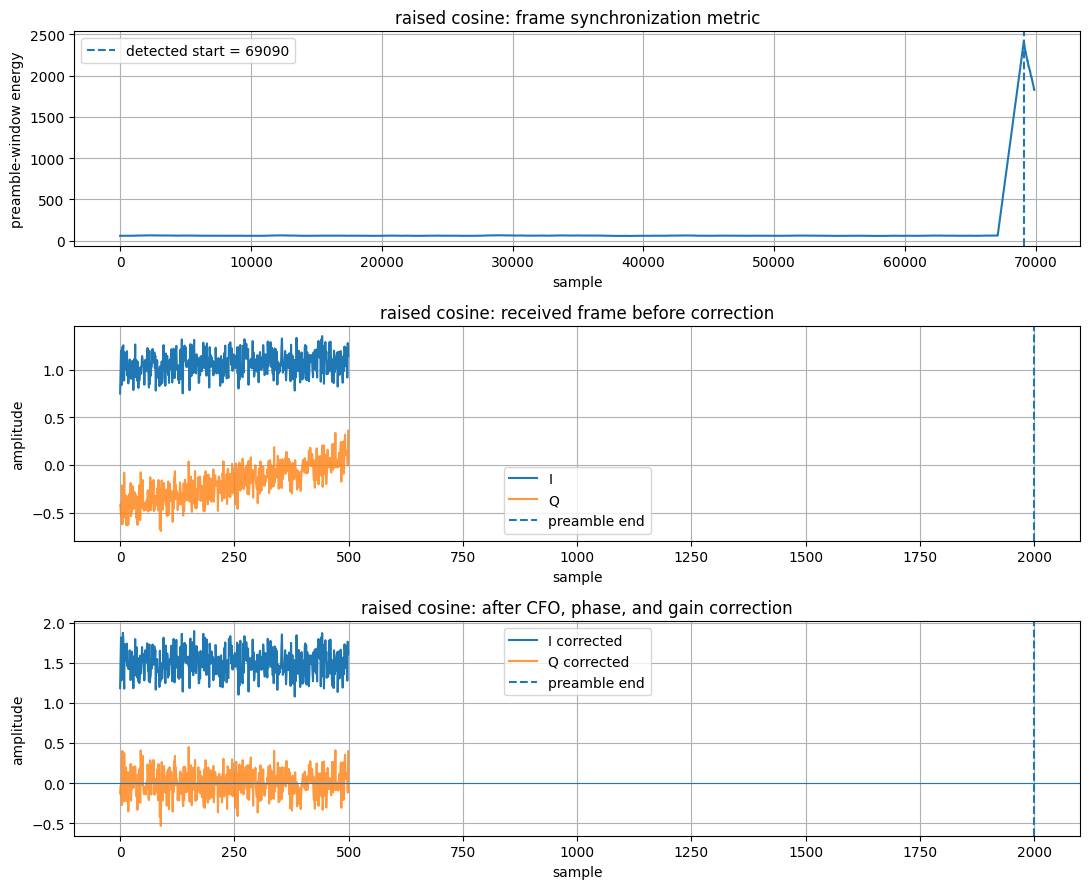

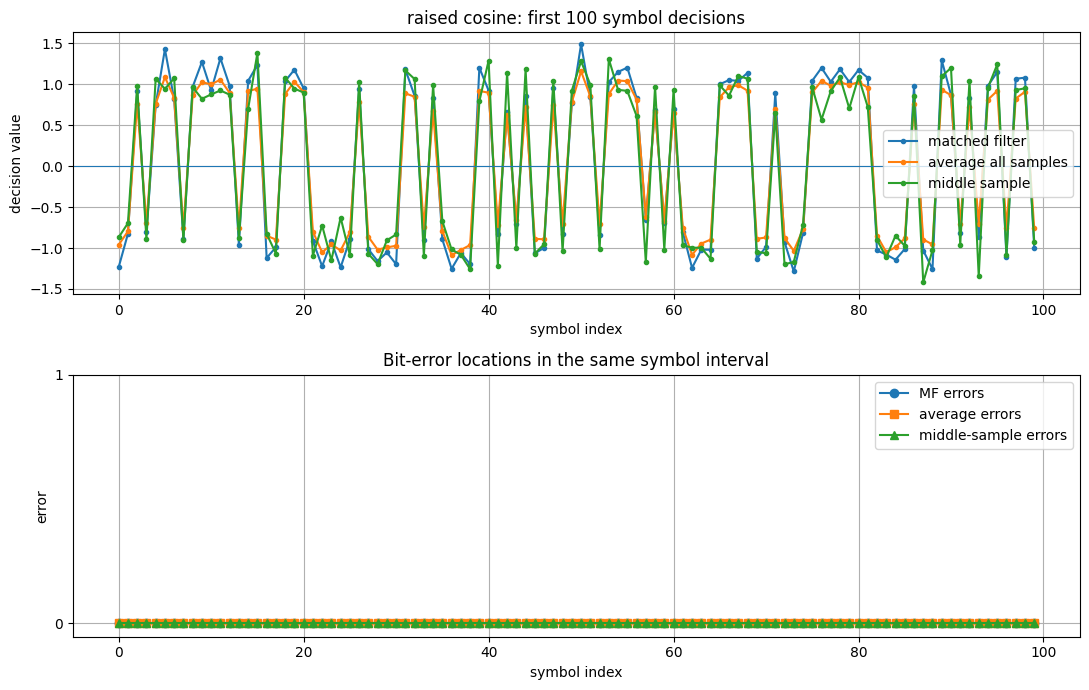

In [16]:
# Plot the main intermediate signals for every pulse.
for name, r in results_by_pulse.items():
    # A useful window around the detected frame start.
    w = min(500, len(r["rx"]) - r["start"])
    if w <= 0:
        continue

    fig, axes = plt.subplots(3, 1, figsize=(11, 9))

    # 1) RX buffer and sync metric.
    power = np.abs(r["rx"]) ** 2
    metric = np.convolve(power, np.ones(PREAMBLE_LEN), mode='valid')
    show_metric = min(len(metric), max(r["start"] + 800, 1000))
    axes[0].plot(np.arange(show_metric), metric[:show_metric])
    axes[0].axvline(r["start"], linestyle="--", label=f"detected start = {r['start']}")
    axes[0].set_title(f"{name}: frame synchronization metric")
    axes[0].set_xlabel("sample")
    axes[0].set_ylabel("preamble-window energy")
    axes[0].grid(True)
    axes[0].legend()

    # 2) Raw received frame.
    axes[1].plot(np.arange(w), r["frame_slice"][:w].real, label="I")
    axes[1].plot(np.arange(w), r["frame_slice"][:w].imag, label="Q", alpha=0.8)
    axes[1].axvline(PREAMBLE_LEN, linestyle="--", label="preamble end")
    axes[1].set_title(f"{name}: received frame before correction")
    axes[1].set_xlabel("sample")
    axes[1].set_ylabel("amplitude")
    axes[1].grid(True)
    axes[1].legend()

    # 3) Corrected frame.
    axes[2].plot(np.arange(w), r["corrected"][:w].real, label="I corrected")
    axes[2].plot(np.arange(w), r["corrected"][:w].imag, label="Q corrected", alpha=0.8)
    axes[2].axhline(0, linewidth=0.8)
    axes[2].axvline(PREAMBLE_LEN, linestyle="--", label="preamble end")
    axes[2].set_title(f"{name}: after CFO, phase, and gain correction")
    axes[2].set_xlabel("sample")
    axes[2].set_ylabel("amplitude")
    axes[2].grid(True)
    axes[2].legend()

    plt.tight_layout()
    plt.show()

    # Matched-filter output and direct detector outputs.
    n_show = min(100, N_BITS)
    k = np.arange(n_show)

    fig, axes = plt.subplots(2, 1, figsize=(11, 7))
    axes[0].plot(k, r["mf_syms"][:n_show].real, ".-", label="matched filter")
    axes[0].plot(k, r["avg_syms"][:n_show].real, ".-", label="average all samples")
    axes[0].plot(k, r["mid_syms"][:n_show].real, ".-", label="middle sample")
    axes[0].axhline(0, linewidth=0.8)
    axes[0].set_title(f"{name}: first {n_show} symbol decisions")
    axes[0].set_xlabel("symbol index")
    axes[0].set_ylabel("decision value")
    axes[0].grid(True)
    axes[0].legend()

    # Error locations for each detector.
    tx = bits[:n_show]
    for method, arr, row in [
        ("MF", r["mf_bits"], 0),
        ("average", r["avg_bits"], 0),
        ("middle", r["mid_bits"], 0),
    ]:
        pass
    mf_err = (r["mf_bits"][:n_show] != tx)
    avg_err = (r["avg_bits"][:n_show] != tx)
    mid_err = (r["mid_bits"][:n_show] != tx)
    axes[1].plot(k, mf_err.astype(int), "o-", label="MF errors")
    axes[1].plot(k, avg_err.astype(int), "s-", label="average errors")
    axes[1].plot(k, mid_err.astype(int), "^-", label="middle-sample errors")
    axes[1].set_yticks([0, 1])
    axes[1].set_xlabel("symbol index")
    axes[1].set_ylabel("error")
    axes[1].set_title("Bit-error locations in the same symbol interval")
    axes[1].grid(True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()


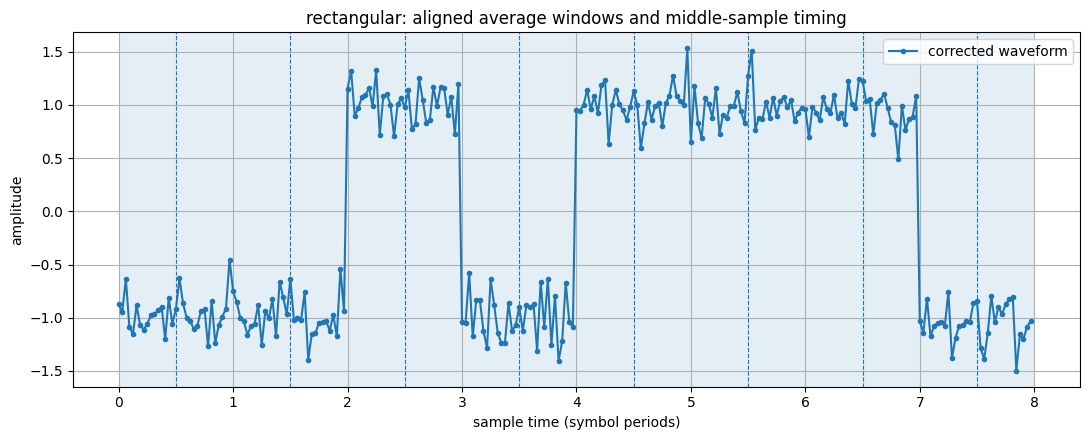

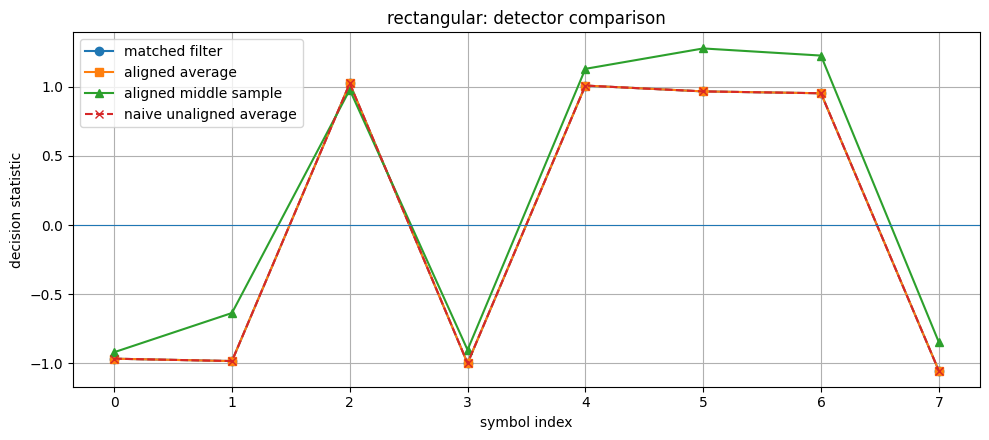

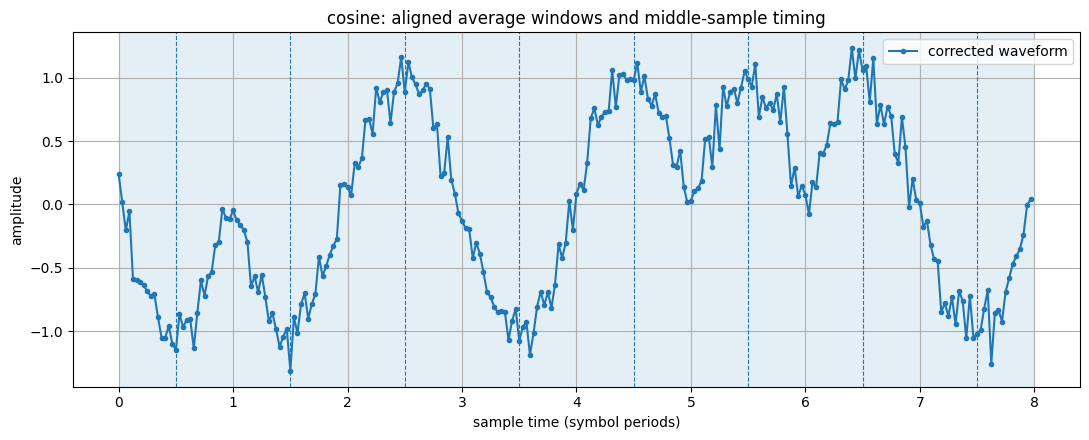

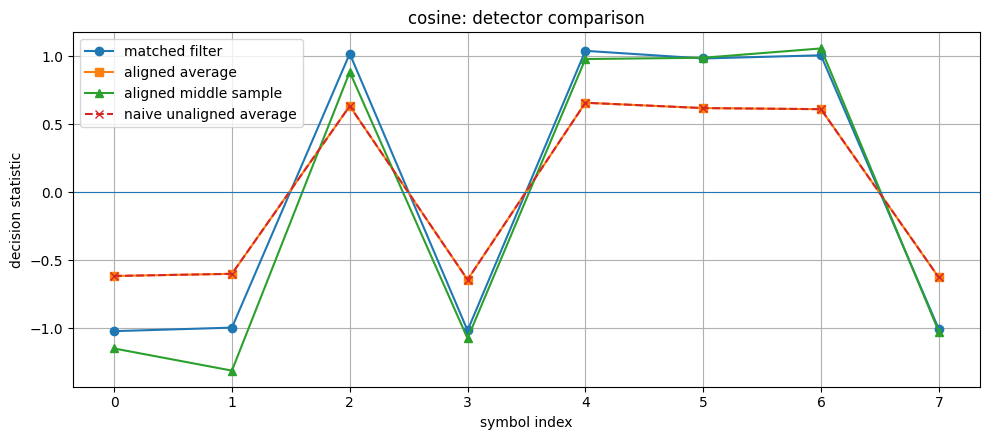

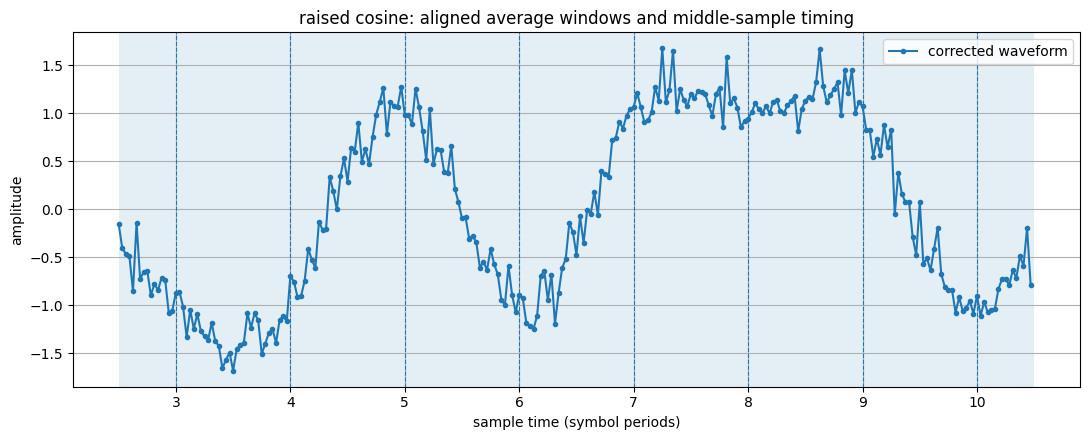

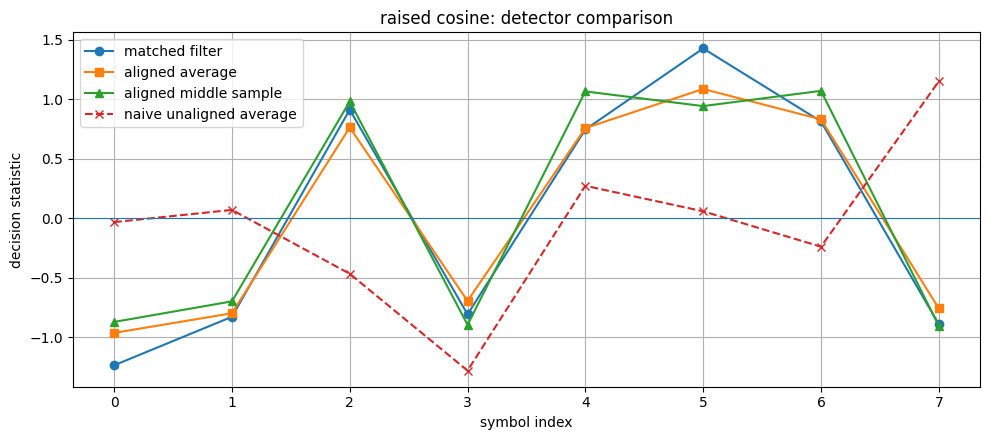

In [17]:
# Show the actual SPS-sample waveform and detector timing.
for name, r in results_by_pulse.items():
    n_symbols = 8
    center = symbol_center_offset(r["pulse"])
    start = max(0, center - SPS // 2)

    samples = r["payload"][start:start + n_symbols * SPS]
    t = (np.arange(len(samples)) + start) / SPS

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(t, samples.real, ".-", label="corrected waveform")

    for k in range(n_symbols):
        symbol_center = (center + k * SPS) / SPS
        ax.axvline(symbol_center, linestyle="--", linewidth=0.8)

        avg_start = center - SPS // 2 + k * SPS
        avg_end = avg_start + SPS
        ax.axvspan(avg_start / SPS, avg_end / SPS, alpha=0.12)

    ax.set_xlabel("sample time (symbol periods)")
    ax.set_ylabel("amplitude")
    ax.set_title(f"{name}: aligned average windows and middle-sample timing")
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Compare all detectors on the same symbols.
    avg = r["avg_syms"][:n_symbols].real
    mid = r["mid_syms"][:n_symbols].real
    mf = r["mf_syms"][:n_symbols].real
    naive = r["naive_avg_syms"][:n_symbols].real
    idx = np.arange(n_symbols)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(idx, mf, "o-", label="matched filter")
    ax.plot(idx, avg, "s-", label="aligned average")
    ax.plot(idx, mid, "^-", label="aligned middle sample")
    ax.plot(idx, naive, "x--", label="naive unaligned average")
    ax.axhline(0, linewidth=0.8)
    ax.set_xlabel("symbol index")
    ax.set_ylabel("decision statistic")
    ax.set_title(f"{name}: detector comparison")
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    plt.show()

## SNR vs BER

This sweep keeps the same pulse shapes and receiver chain but repeats the channel experiment at several SNR values. It reports three receivers:

- **Matched filter:** correlation with the known pulse, then one sample per symbol.
- **Average:** average all `SPS` corrected waveform samples in each symbol interval.
- **Middle:** use only the center sample in each symbol interval.

Each point is averaged over several independent channel/noise realizations. The sweep uses the same CFO and synchronization/correction algorithms as the main experiment.


rectangular      CFO est:    299.4 Hz | MF BER: 0.0000e+00 | aligned average BER: 0.0000e+00 | aligned middle BER: 8.5250e-02 | naive average BER: 0.0000e+00
cosine           CFO est:    299.6 Hz | MF BER: 0.0000e+00 | aligned average BER: 0.0000e+00 | aligned middle BER: 2.3500e-02 | naive average BER: 0.0000e+00
raised cosine    CFO est:    292.8 Hz | MF BER: 4.6725e-01 | aligned average BER: 4.6500e-01 | aligned middle BER: 4.7175e-01 | naive average BER: 4.9500e-01
rectangular      CFO est:    302.6 Hz | MF BER: 2.5000e-04 | aligned average BER: 2.5000e-04 | aligned middle BER: 1.2950e-01 | naive average BER: 2.5000e-04
cosine           CFO est:    304.3 Hz | MF BER: 1.0125e-01 | aligned average BER: 1.0350e-01 | aligned middle BER: 1.9050e-01 | naive average BER: 1.0350e-01
raised cosine    CFO est:    294.8 Hz | MF BER: 2.5600e-01 | aligned average BER: 2.5975e-01 | aligned middle BER: 3.1175e-01 | naive average BER: 4.7575e-01
rectangular      CFO est:    298.0 Hz | MF BER: 0.00

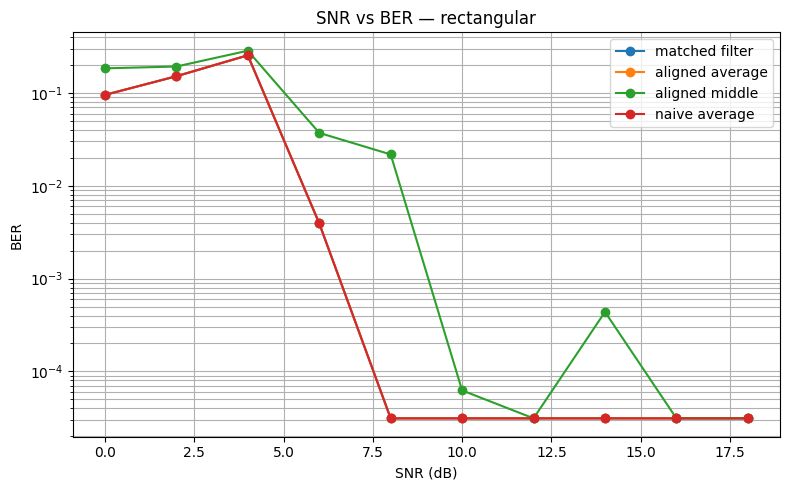

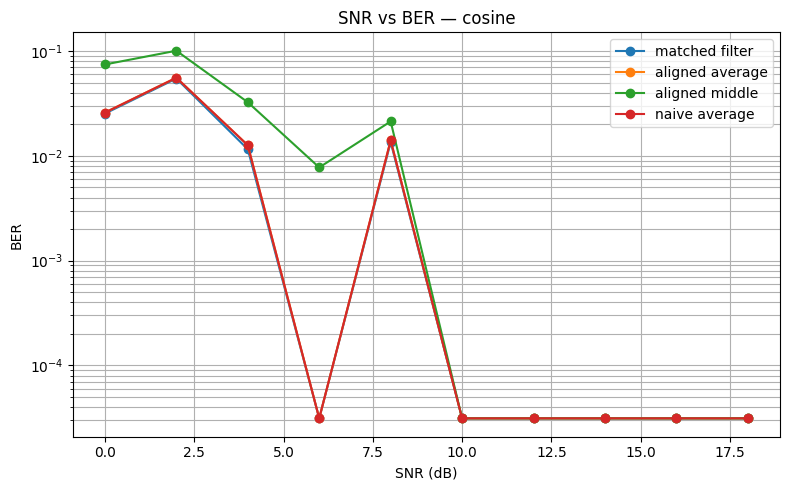

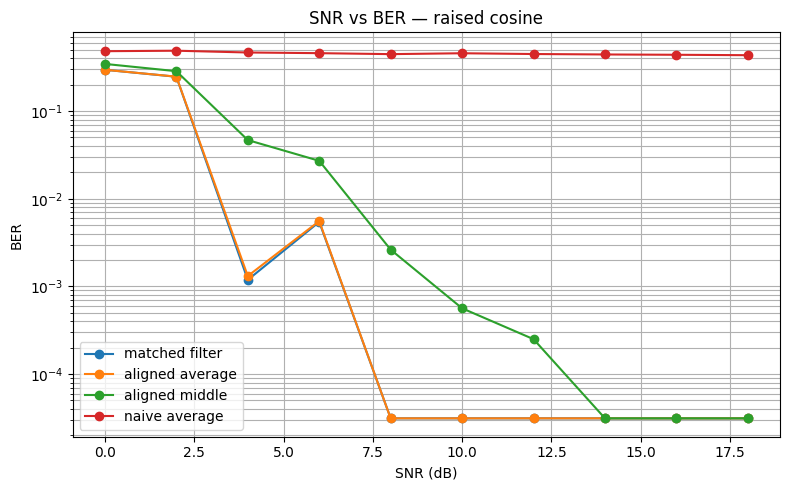

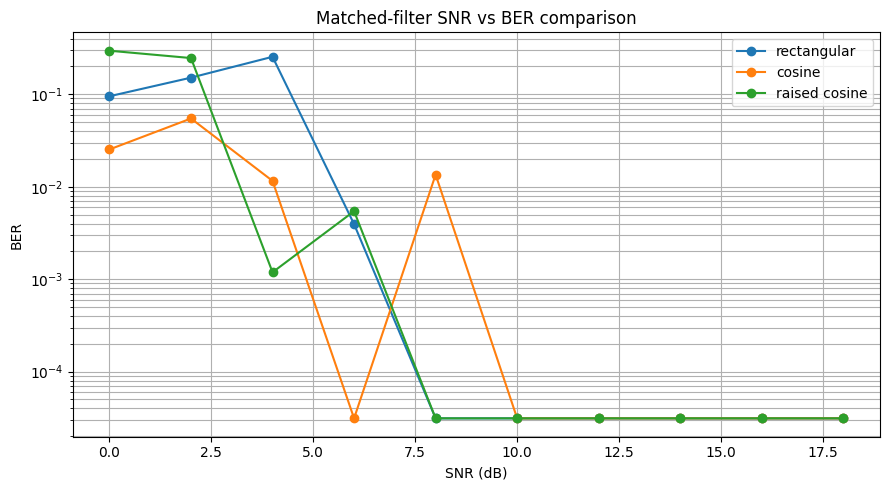

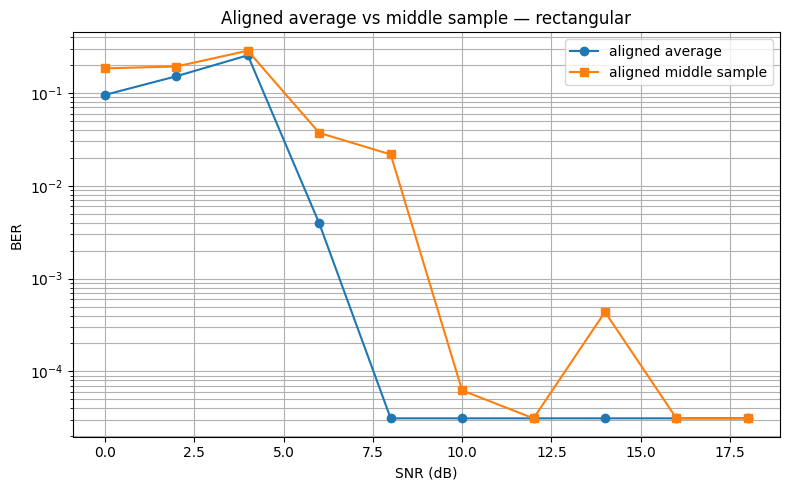

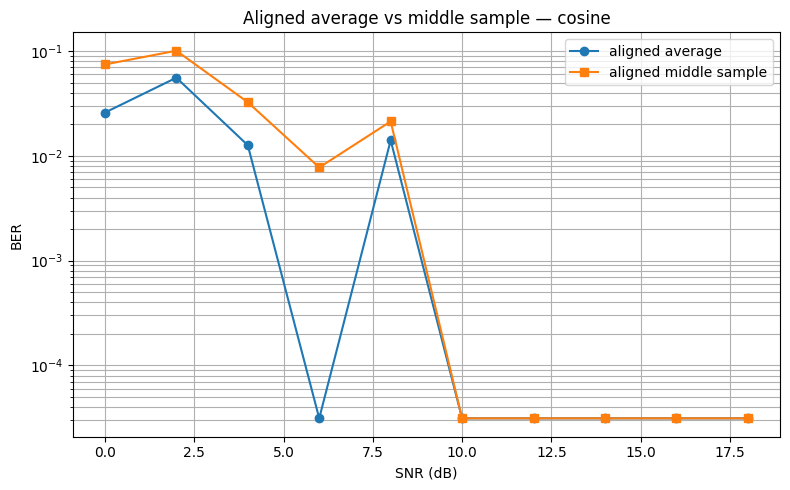

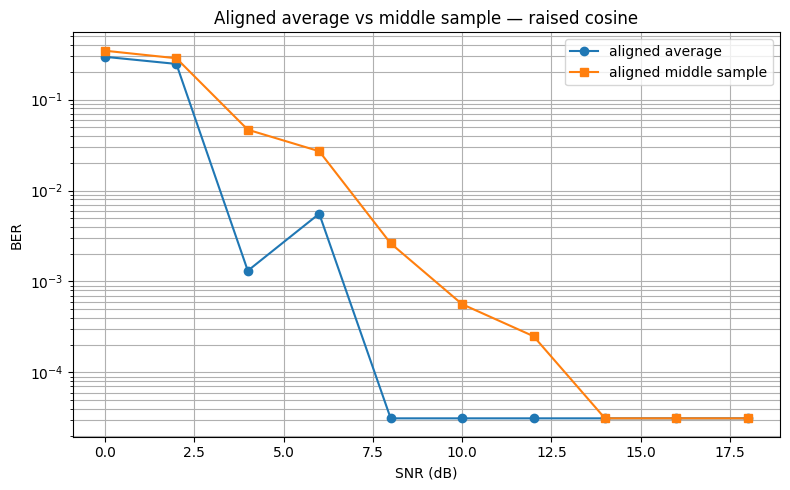

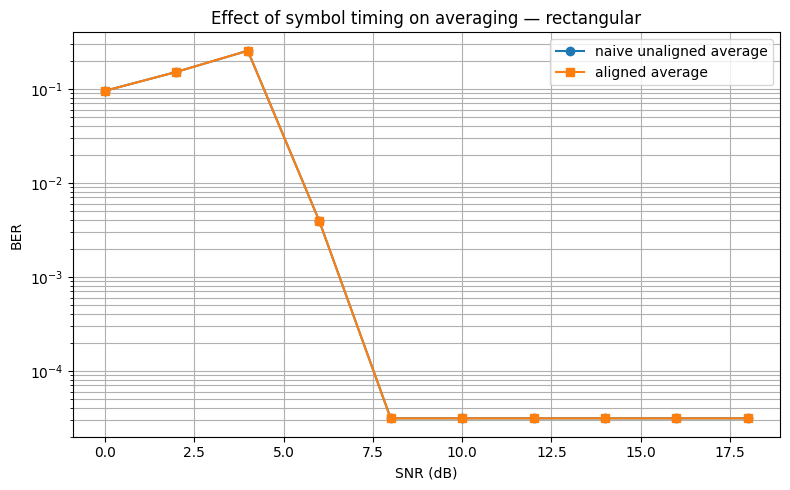

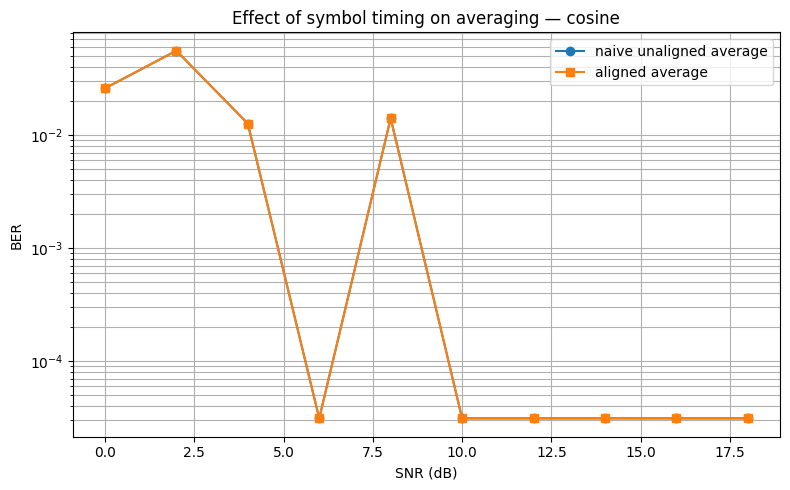

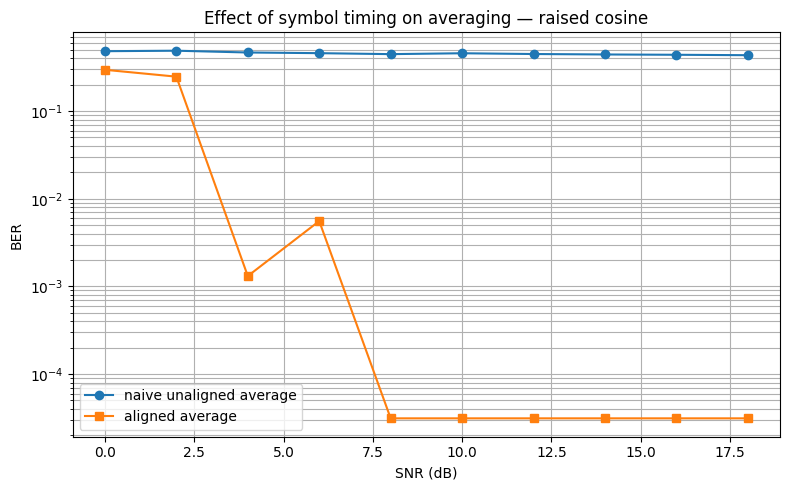

In [18]:
# SNR sweep: BER for all pulse shapes and detector methods.
#
# Methods:
#   1. matched filter
#   2. timing-aligned average of SPS samples
#   3. timing-aligned middle sample
#   4. intentionally naive/unaligned average

SNR_SWEEP_DB = np.arange(0, 19, 2)
SNR_TRIALS = 4

ber_sweep = {
    name: {
        "matched filter": [],
        "aligned average": [],
        "aligned middle": [],
        "naive average": []
    }
    for name in pulses
}

rng_state = np.random.get_state()
np.random.seed(2026)

for snr in SNR_SWEEP_DB:
    accum = {
        name: {
            "matched filter": [],
            "aligned average": [],
            "aligned middle": [],
            "naive average": []
        }
        for name in pulses
    }

    for trial in range(SNR_TRIALS):
        trial_bits = generate_bits(N_BITS)

        for name, pulse in pulses.items():
            rr = run_pulse(
                name, pulse, trial_bits, SPS,
                PREAMBLE_LEN, PREAMBLE_SCALE,
                FS, CFO_HZ, snr
            )

            accum[name]["matched filter"].append(rr["mf_ber"])
            accum[name]["aligned average"].append(rr["avg_ber"])
            accum[name]["aligned middle"].append(rr["mid_ber"])
            accum[name]["naive average"].append(rr["naive_avg_ber"])

    for name in pulses:
        for method in ber_sweep[name]:
            ber_sweep[name][method].append(np.mean(accum[name][method]))

np.random.set_state(rng_state)

# 1. All detector methods for each pulse.
for name in pulses:
    fig, ax = plt.subplots(figsize=(8, 5))
    for method, vals in ber_sweep[name].items():
        ax.semilogy(
            SNR_SWEEP_DB,
            np.maximum(vals, 0.5 / (N_BITS * SNR_TRIALS)),
            "o-",
            label=method
        )

    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("BER")
    ax.set_title(f"SNR vs BER — {name}")
    ax.grid(True, which="both")
    ax.legend()
    plt.tight_layout()
    plt.show()

# 2. Matched-filter comparison between pulse shapes.
fig, ax = plt.subplots(figsize=(9, 5))
for name in pulses:
    ax.semilogy(
        SNR_SWEEP_DB,
        np.maximum(
            ber_sweep[name]["matched filter"],
            0.5 / (N_BITS * SNR_TRIALS)
        ),
        "o-",
        label=name
    )

ax.set_xlabel("SNR (dB)")
ax.set_ylabel("BER")
ax.set_title("Matched-filter SNR vs BER comparison")
ax.grid(True, which="both")
ax.legend()
plt.tight_layout()
plt.show()

# 3. Aligned average versus aligned middle.
for name in pulses:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.semilogy(
        SNR_SWEEP_DB,
        np.maximum(
            ber_sweep[name]["aligned average"],
            0.5 / (N_BITS * SNR_TRIALS)
        ),
        "o-",
        label="aligned average"
    )
    ax.semilogy(
        SNR_SWEEP_DB,
        np.maximum(
            ber_sweep[name]["aligned middle"],
            0.5 / (N_BITS * SNR_TRIALS)
        ),
        "s-",
        label="aligned middle sample"
    )

    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("BER")
    ax.set_title(f"Aligned average vs middle sample — {name}")
    ax.grid(True, which="both")
    ax.legend()
    plt.tight_layout()
    plt.show()

# 4. Demonstrate the timing problem directly.
for name in pulses:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.semilogy(
        SNR_SWEEP_DB,
        np.maximum(
            ber_sweep[name]["naive average"],
            0.5 / (N_BITS * SNR_TRIALS)
        ),
        "o-",
        label="naive unaligned average"
    )
    ax.semilogy(
        SNR_SWEEP_DB,
        np.maximum(
            ber_sweep[name]["aligned average"],
            0.5 / (N_BITS * SNR_TRIALS)
        ),
        "s-",
        label="aligned average"
    )

    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("BER")
    ax.set_title(f"Effect of symbol timing on averaging — {name}")
    ax.grid(True, which="both")
    ax.legend()
    plt.tight_layout()
    plt.show()

## Background

**Why sharp edges cost bandwidth.** A signal's spectrum is its Fourier transform, and an
instantaneous jump in amplitude -- exactly what the rectangular pulse does at every symbol
boundary -- requires energy at arbitrarily high frequencies to reproduce. The Fourier
transform of a rectangular pulse of duration $T$ is a sinc function, whose sidelobes decay
only as $1/f$: slowly enough that a real system has to either accept significant
out-of-band leakage or filter it away after the fact. The cosine pulse's edges are smoother
-- its value and slope both go to zero at the boundary -- and that extra smoothness is
exactly why its spectrum decays faster than the rectangular pulse's, as Task 4's plot
showed. It's still confined to one symbol period, though, so there's a limit to how smooth
its edges can be.

**Nyquist's zero-ISI criterion.** The raised-cosine pulse spreads across several symbol
periods but is designed so that at every *other* symbol's sampling instant, its value is
exactly zero -- Task 5 confirmed exactly this. That's Nyquist's criterion for ISI-free
transmission: a pulse doesn't need to be zero everywhere outside its own symbol period, it
only needs to cross zero at every *other* symbol's sampling instant. Sample at the wrong
time, even by a fraction of a symbol period, and that zero-crossing property is lost --
neighboring symbols' tails no longer cancel, and you get real interference. This is exactly
why frame sync matters as much as it does: a raised-cosine pulse is far less forgiving of
timing error than a rectangular one.

**The role of $\beta$.** The roll-off factor trades bandwidth against time-domain decay.
$\beta \to 0$ gives the narrowest possible bandwidth (approaching the ideal $\text{sinc}$
pulse), but the pulse's tails decay very slowly in that limit, making it extremely
sensitive to timing error. $\beta \to 1$ gives the fastest-decaying tails -- more forgiving
of timing error -- at the cost of roughly twice the bandwidth of the zero-roll-off case.
Real systems pick something in between (0.35 here, a value used in several real
standards) as a practical compromise.

**Why the frequency estimator uses two blocks, not adjacent samples.** Comparing every
sample to its immediate neighbor (a 1-sample lag) works in principle, but the phase
difference it's measuring is tiny relative to the noise sitting on top of it. Comparing two
much-further-apart blocks of the preamble instead makes that phase difference proportionally
much larger for the same noise level, at the cost of a smaller *unambiguous* range (a phase
difference beyond $\pm\pi$ can't be told apart from wrapping around) -- a trade that's easy
to afford here since the actual frequency offsets in play are nowhere near that limit.

## Reflection Questions

1. Why does the rectangular pulse's instant on/off transition lead to a spectrum that decays
   so slowly with frequency?
2. The cosine pulse tapers smoothly to zero at both edges. Does that completely eliminate
   spectral leakage outside the symbol's nominal bandwidth, or just reduce it? Why?
3. The raised-cosine pulse deliberately spreads one symbol's energy across several
   neighboring symbol periods -- yet Task 5 showed no interference at the correct sampling
   instant. In your own words, why doesn't the overlap in time cause a problem?
4. Suppose the receiver sampled the raised-cosine matched-filter output slightly off from
   the correct instant -- not exactly at the peak. Would every value of $\beta$ be equally
   forgiving of that timing error, or would some be more sensitive than others?
5. All three pulses in this worksheet were normalized so that BPSK's matched-filter output
   lands on the same $\pm 1$ regardless of which pulse was used. Given that, what's actually
   being bought by moving to a more complicated pulse than the rectangular one?

## Answers to Reflection Questions

**1. Why does the rectangular pulse decay slowly in frequency?**
Its instant on/off jump is a discontinuity. The Fourier transform of a rectangle is a sinc, whose sidelobes fall only as $1/f$, so a lot of energy stays at high frequencies.

**2. Does the cosine pulse completely remove leakage?**
No, it only reduces it. The pulse is still limited to one symbol period, and a signal that is finite in time can never be strictly band-limited. Its edges are smooth (value and slope are zero), so the sidelobes fall faster than $1/f$, but they never reach zero.

**3. Why doesn't the time overlap of raised-cosine pulses cause ISI?**
The pulse is zero at every whole-symbol multiple away from its peak (Nyquist zero-ISI criterion). At the correct sampling instant, all neighbouring pulses are exactly zero, so only the current symbol's peak contributes. The overlap exists in between the samples, but not at them.

**4. Is every $\beta$ equally forgiving of a timing error?**
No. A small $\beta$ has slowly decaying tails and steep zero-crossings, so a small timing error lets many neighbouring symbols leak in and causes a lot of ISI. A larger $\beta$ has faster-decaying tails and is more tolerant, but uses more bandwidth.

**5. What is gained by a more complicated pulse if the matched-filter output is the same $\pm 1$?**
Not better noise performance, since the matched-filter BER is about the same for all three. What is gained is spectral efficiency: much less bandwidth and out-of-band leakage for the same symbol rate, while still having zero ISI at the sampling instants. The price is a longer pulse and less tolerance to timing error.

## Things to Try

- Set `SNR_DB = None` and `CFO_HZ = 0` to confirm all three pulses recover with zero errors.
- Lower `SNR_DB` and compare the three detectors: matched filter, average of all samples, and middle sample.
- Increase `CFO_HZ` and observe the received waveform before and after correction.
- Change `RC_BETA` and compare the raised-cosine time waveform, spectrum, zero-ISI samples, and BER.
- Change `RC_SPAN` and observe the trade-off between a longer pulse and its truncated tails.
- Set `RANDOM_SEED` to an integer if you want repeatable plots and BER results.
